# Distributed and Secure Kernel-Based Quantum Machine Learning — Reproduction

Paper: A. Swaminathan and M. Akgün, [arXiv 2408.10265](https://arxiv.org/abs/2408.10265) (v3). Authors' code: [mdppml/distributed-secure-kernel-based-QML](https://github.com/mdppml/distributed-secure-kernel-based-QML).

This notebook walks through the reproduction as an argument: what the paper claims, how we test it, what the evidence shows, and what it does not show. Every headline number is either recomputed live in this notebook or loaded from the stored sweep records in `results/`, and live runs are checked against those records.

**Runtime.** About 2–3 minutes on a laptop CPU (measured: 135 s on a 10-core laptop). What runs live and what is loaded:

| Part | Live in this notebook | Loaded from `results/` (full 5-seed sweeps) |
|---|---|---|
| Sanity checks (kernel identity, per-shot Aer, shot statistics, feature maps, photonic kernel) | all | — |
| Table 1, Wine and Parkinson's, paper protocol | 5 seeds | — |
| Table 1, Framingham | — | 5 seeds (about 50 s per seed per config) |
| Fig. 3 (noise) | — | 5 seeds (40–320 s per seed) |
| Fig. 4 (shots, Digits) | 5 seeds | — |
| Fig. 5 (random-Fourier-feature error) | — | figure (d = 100,000 needs minutes) |
| Fair comparison, Wine and Parkinson's | 5 seeds | — |
| Fair comparison, Framingham | — | 5 seeds (4–6 min per seed per config) |
| MerLin photonic kernel, Wine and Parkinson's | 5 seeds | — |
| MerLin photonic kernel, Framingham and Digits | — | 5 seeds (2–10 min per seed) |

Run it from `papers/distributed_secure_kernels/` with the paper's environment (`pip install -r requirements.txt`) and the datasets under `data/distributed_secure_kernels/` (see the README, "Data").

In [1]:
import contextlib
import io
import json
import logging
import sys
import tempfile
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from scipy import stats

PAPER_DIR = Path.cwd()
if not (PAPER_DIR / "lib" / "runner.py").exists():
    raise RuntimeError("Start the notebook from papers/distributed_secure_kernels/")
sys.path[:0] = [str(PAPER_DIR.parent), str(PAPER_DIR.parents[1])]

from distributed_secure_kernels.lib.data import build_dataset  # noqa: E402
from distributed_secure_kernels.lib.encoding import qubits_per_sample  # noqa: E402
from distributed_secure_kernels.lib.feature_map_checks import (  # noqa: E402
    check_polynomial,
)
from distributed_secure_kernels.lib.kernels import (  # noqa: E402
    cosine_kernel,
    finite_shot_kernel,
    squared_overlap_kernel,
    swap_test_zero_probability,
)
from distributed_secure_kernels.lib.photonic_merlin import (  # noqa: E402
    PhotonicSwapTest,
    encode_registers,
    register_modes,
)
from distributed_secure_kernels.lib.protocol import (  # noqa: E402
    centralised_circuit,
    distributed_circuit,
    independent_seed,
    run_ancilla_zeros,
)
from distributed_secure_kernels.lib.runner import train_and_evaluate  # noqa: E402
from distributed_secure_kernels.utils.plot_style import (  # noqa: E402
    EXACT,
    INK,
    MUTED,
    OURS,
    PAPER,
    REFERENCE,
    style_axes,
)
from runtime_lib.config import deep_update, load_config  # noqa: E402
from runtime_lib.dtypes import resolve_config_dtypes  # noqa: E402
from runtime_lib.seed import seed_everything  # noqa: E402

%matplotlib inline

pd.set_option("display.precision", 4)
logging.disable(logging.INFO)  # the runs still write their own run.log files
SEEDS = [0, 1, 2, 3, 4]
RESULTS = PAPER_DIR / "results"
STORED = json.loads((RESULTS / "sweep_results.json").read_text())
PAPER_VALUES = {
    row["label"]: row
    for row in json.loads((RESULTS / "paper_comparison.json").read_text())
}
LIVE_DIR = Path(tempfile.mkdtemp(prefix="dsk_notebook_"))
NOTEBOOK_START = time.perf_counter()
print(
    "Stored sweeps:",
    ", ".join(f"{k} ({v['runs']} runs, {v['coverage']})" for k, v in STORED.items()),
)

Stored sweeps: fair_comparison (25 runs, COMPLETE SWEEP), merlin_original (20 runs, COMPLETE SWEEP), noise_decomposed_initialize (10 runs, COMPLETE SWEEP), noise_original (10 runs, COMPLETE SWEEP), shots_original (5 runs, COMPLETE SWEEP), table1_corrected (30 runs, COMPLETE SWEEP), table1_original (30 runs, COMPLETE SWEEP)


In [2]:
def load_cfg(config_name: str, seed: int) -> dict:
    # Same merge as the shared runtime: defaults.json, then the named config.
    cfg = deep_update(
        load_config(PAPER_DIR / "configs" / "defaults.json"),
        load_config(PAPER_DIR / "configs" / config_name),
    )
    cfg["seed"] = seed
    return resolve_config_dtypes(cfg)


def run_live(config_name: str, seeds=SEEDS) -> dict[int, dict]:
    # One run per seed through lib.runner.train_and_evaluate; returns {seed: metrics}.
    out = {}
    for seed in seeds:
        cfg = load_cfg(config_name, seed)
        seed_everything(seed)
        run_dir = LIVE_DIR / f"{Path(config_name).stem}_seed{seed}"
        run_dir.mkdir(parents=True, exist_ok=True)
        with contextlib.redirect_stderr(io.StringIO()):
            train_and_evaluate(cfg, run_dir)
        out[seed] = json.loads((run_dir / "metrics.json").read_text())
    return out


def summary_of(metrics: dict, method: str, model: str = "kernel_svm") -> dict:
    # Fold summary of one method and model inside one run's metrics.json.
    outcome = metrics["methods"][method]
    if model == "kernel_svm":
        return outcome["kernel_svm"]
    pca = outcome["kernel_pca"]
    if model == "kernel_pca_best_on_test_folds":
        return pca["best_on_test_folds"]
    if model == "kernel_pca_nested_cv":
        return pca
    return pca["per_component_count"][model.split("_")[2]]


def live_values(
    runs: dict, method: str, model: str = "kernel_svm", metric: str = "accuracy"
) -> np.ndarray:
    # Per-seed 5-fold mean, in seed order.
    return np.array(
        [summary_of(runs[s], method, model)[metric]["mean"] for s in sorted(runs)]
    )


def stored_values(
    sweep: str,
    candidate: str,
    method: str,
    model: str = "kernel_svm",
    metric: str = "accuracy",
) -> np.ndarray:
    for row in STORED[sweep]["rows"]:
        if (row["candidate"], row["method"], row["model"]) == (
            candidate,
            method,
            model,
        ):
            return np.array([row[metric]["per_seed"][str(s)] for s in SEEDS])
    raise KeyError((sweep, candidate, method, model))


def check_against_stored(runs: dict, sweep: str, candidate: str, pairs) -> float:
    # Largest |live - stored| over the given (method, model) pairs and both metrics.
    gaps = [
        np.max(
            np.abs(
                live_values(runs, m, mod, metric)
                - stored_values(sweep, candidate, m, mod, metric)
            )
        )
        for m, mod in pairs
        for metric in ("accuracy", "balanced_accuracy")
    ]
    return float(max(gaps))


def decide(first: np.ndarray, second: np.ndarray) -> dict:
    # Frozen rule: equivalent when |difference| <= 2 sigma_pooled (seed std, ddof = 1).
    delta = first.mean() - second.mean()
    pooled = np.sqrt((first.std(ddof=1) ** 2 + second.std(ddof=1) ** 2) / 2)
    if pooled == 0:
        verdict = (
            "equivalent"
            if abs(delta) < 1e-12
            else ("first higher" if delta > 0 else "second higher")
        )
    else:
        verdict = (
            "equivalent"
            if abs(delta) <= 2 * pooled
            else ("first higher" if delta > 0 else "second higher")
        )
    return {"difference": delta, "2 sigma pooled": 2 * pooled, "verdict": verdict}


def mean_std(values: np.ndarray) -> str:
    return f"{values.mean():.4f} ± {values.std(ddof=1):.4f}"

## 1. Problem statement and paper claim

Two data holders (Alice and Bob) want a kernel between their private samples without revealing them. Each amplitude-encodes a sample into a quantum state; a helper distributes Bell pairs; both teleport their states to a server, which estimates the kernel with a **swap test**. The kernel matrix then feeds a kernel SVM or kernel PCA.

The paper's claims, and where this notebook tests them:

| Claim (paper) | Test | Section |
|---|---|---|
| The distributed circuit computes the same kernel as a centralised swap test (App. A) | per-shot Aer runs of the authors' circuits | 4 |
| Distributed quantum accuracy is *comparable* to centralised quantum and classical accuracy; centralised classical is generally highest (Table 1) | Table 1 with 5 seeds; fair classical baseline | 6–8 |
| Depolarizing noise lowers accuracy (Fig. 3); more shots raise it (Fig. 4) | noise and shots sweeps | 7, 10 |
| The proposed feature maps give the polynomial, RBF and Laplacian kernels (Theorems 1–6); RFF error decays as 1/√D (Fig. 5) | numerical identity checks; Fig. 5 | 4, 7 |
| Secure against semi-honest parties (Sec. 6.3) | an argument, not an experiment; out of scope here | 12 |

The paper claims *comparable*, not better, accuracy: there is no quantum-advantage claim to test.

**Research question.** Does the distributed quantum kernel (i) give the same accuracy as the centralised quantum kernel and (ii) reach accuracy comparable to a competently tuned classical kernel evaluated under the same leak-free protocol?

**What would weaken the claim.** (i) is weakened if distributed and centralised differ by more than 2 σ of the seed spread. (ii) is weakened if a tuned classical SVM is higher by more than 2 σ, or if the quantum kernel does no better than predicting the majority class.

## 2. Data, splits, metrics, and evaluation protocol

Four public datasets, the same files the authors' code reads (checksums in `data/distributed_secure_kernels/*/SHA256SUMS`). Features are standardised, zero-padded to a power of two and amplitude-encoded.

Two evaluation protocols are used, and every table says which one:

- **Paper protocol** (faithful reproduction). The authors' pipeline: minority oversampling (`RandomOverSampler(0.6)`) *before* the 80 % subset split and before cross-validation, the scaler fitted on the evaluated subset, SVM with C = 1, and kernel PCA reported as the best of 2–7 components *chosen on the evaluation folds*. Oversampled copies of test samples can sit in the training folds, and the component choice uses test folds, so this protocol is optimistic.
- **Corrected protocol** (our control). Oversampling only inside training folds, the scaler fitted on training folds, C and the component count chosen by inner 5-fold CV on the training folds. No test-fold information reaches any selection.

**Metric.** Stratified 5-fold cross-validation accuracy on the evaluated subset (higher is better), with balanced accuracy as a second metric (needed for Framingham, see below). **Seeds** 0–4 change the shot noise and the oversampling draw; the subset split (`random_state = 42`) and fold assignment (`random_state = 0`) are the authors'. **Aggregate:** mean over seeds of the 5-fold mean; **variability:** standard deviation over seeds (ddof = 1). **Decision rules** (fixed before the runs): a paper value is *matched* when our mean is within the paper's fold std (± 0.02 when the paper gives none); two of our systems are *equivalent* when their difference is within 2 σ_pooled of the seed spread.

In [3]:
rows = []
for name, config in [
    ("wine", "accuracy_wine_original.json"),
    ("parkinsons", "accuracy_parkinsons_original.json"),
    ("framingham", "accuracy_framingham_original.json"),
    ("digits", "shots_digits_original.json"),
]:
    for protocol in ("paper", "corrected") if name != "digits" else ("paper",):
        cfg = load_cfg(config, seed=0)
        cfg["dataset"]["protocol"] = protocol
        data = build_dataset(cfg, "train")
        counts = data.metadata["class_counts"]
        rows.append(
            {
                "dataset": name,
                "protocol": protocol,
                "samples evaluated": data.features.shape[0],
                "features": data.features.shape[1],
                "qubits per sample": qubits_per_sample(data.features.shape[1]),
                "classes": len(counts),
                "majority rate": max(counts.values()) / sum(counts.values()),
            }
        )
pd.DataFrame(rows)

,dataset,protocol,samples evaluated,features,qubits per sample,classes,majority rate
0,wine,paper,142,13,4,3,0.4014
1,wine,corrected,142,13,4,3,0.4014
2,parkinsons,paper,188,22,5,2,0.6277
3,parkinsons,corrected,156,22,5,2,0.7564
4,framingham,paper,4066,14,4,2,0.6249
5,framingham,corrected,2999,14,4,2,0.8473
6,digits,paper,100,64,6,10,0.1000


**Reading the table.** Under the paper protocol the oversampled minority rows are part of the evaluated subset, so the majority rate drops (Framingham 0.625 instead of 0.847). Under the corrected protocol the evaluated subset is the real data and oversampling happens inside each training fold, so Framingham is strongly imbalanced: a classifier that always predicts "no heart disease" already scores 0.847 accuracy. That is why balanced accuracy (the mean of per-class recalls, 0.5 for a constant predictor on two classes) is reported next to accuracy.

## 3. Minimum mathematics

**Encoding.** A standardised sample $x \in \mathbb{R}^d$ is zero-padded to $2^n$ entries ($n = \lceil \log_2 d \rceil$), permuted by a fixed shared permutation, and normalised: $|\psi(x)\rangle = \sum_i \tfrac{x_i}{\lVert x\rVert} |i\rangle$.

**Swap test.** With one ancilla, two Hadamards and $n$ controlled swaps, the ancilla reads 0 with probability
$$p_0 = \tfrac12 + \tfrac12\,|\langle \psi(x) | \psi(y)\rangle|^2 .$$
With $M$ shots and $Z$ zeros, the authors' estimate is $\hat K = \max(0,\, 2Z/M - 1)$, so $\hat K$ has standard deviation $2\sqrt{p_0(1-p_0)/M}$.

**What the kernel is.** $|\langle \psi(x)|\psi(y)\rangle|^2 = \left(\tfrac{x\cdot y}{\lVert x\rVert \lVert y\rVert}\right)^2$: the *squared* cosine similarity of the standardised features. The paper calls it the "linear kernel"; it is a fixed classical kernel with no hyperparameter. The distributed protocol does not change it: teleportation moves the states to the server, and the server runs the same swap test on $4n+1$ qubits (authors' code).

**Simulation shortcut (our deviation).** Per-shot simulation of the authors' circuit costs 8–13 s per kernel entry for the larger datasets. Without noise teleportation is exact, so each kernel entry is drawn as $\hat K$ from $Z \sim \mathrm{Binomial}(M, p_0)$ computed exactly. Section 4 checks that the authors' circuit, simulated shot by shot, follows that law. With noise, the exact $p_0$ comes from the per-qubit teleportation channel and the swap-test observable of the transpiled noisy circuit (`lib/noise.py`); this was checked the same way against per-shot Aer runs at 1 % and 5 % noise (README, "Results").

## 4. Known-answer sanity checks

Four checks, each with a known answer, before any accuracy is computed.

**4.1 The swap-test kernel is the squared cosine similarity** (on standardised Wine features).

In [4]:
wine = build_dataset(load_cfg("accuracy_wine_original.json", seed=0), "train")
kernel = squared_overlap_kernel(wine.features, wine.features)
cosine = cosine_kernel(wine.features, wine.features)
print(f"max |K - cos^2|           = {np.max(np.abs(kernel - cosine**2)):.1e}")
print(
    f"diagonal of K             = {kernel.diagonal().min():.6f} .. {kernel.diagonal().max():.6f}"
)
print(
    f"off-diagonal K, quartiles = {np.round(np.quantile(kernel[np.triu_indices_from(kernel, 1)], [0.25, 0.5, 0.75]), 3)}"
)

max |K - cos^2|           = 0.0e+00
diagonal of K             = 1.000000 .. 1.000000
off-diagonal K, quartiles = [0.034 0.13  0.291]


**4.2 The authors' distributed circuit follows the binomial law of a swap test.** We simulate the authors' teleportation + swap-test circuit shot by shot with Qiskit Aer (no shortcut) on 20 random pairs of 2-qubit states, 1,024 shots each, and do the same for the centralised circuit. If both circuits return $p_0 = \tfrac12 + \tfrac12|\langle a|b\rangle|^2$, the zero counts follow $\mathrm{Binomial}(1024, p_0)$ and the χ² statistic below has 20 degrees of freedom. Aer seeds are spaced (`independent_seed`) because Aer seeds shot $i$ with `seed + i`: nearby seeds would reuse the same random stream.

In [5]:
rng = np.random.default_rng(2024)
shots, pairs = 1024, 20
records = []
for index in range(pairs):
    a, b = rng.normal(size=4), rng.normal(size=4)
    a, b = a / np.linalg.norm(a), b / np.linalg.norm(b)
    p0 = 0.5 + 0.5 * (a @ b) ** 2
    zeros_distributed = run_ancilla_zeros(
        distributed_circuit(a, b), shots, 0.0, independent_seed(1, index)
    )
    zeros_centralised = run_ancilla_zeros(
        centralised_circuit(a, b), shots, 0.0, independent_seed(2, index)
    )
    records.append(
        {"p0": p0, "distributed": zeros_distributed, "centralised": zeros_centralised}
    )
aer = pd.DataFrame(records)
expected, variance = shots * aer["p0"], shots * aer["p0"] * (1 - aer["p0"])
for circuit in ("distributed", "centralised"):
    chi2 = float((((aer[circuit] - expected) ** 2) / variance).sum())
    print(
        f"{circuit:12s}: chi2 = {chi2:5.1f} on {pairs} dof, p = {stats.chi2.sf(chi2, pairs):.2f}"
    )
aer.head()

distributed : chi2 =  20.7 on 20 dof, p = 0.41
centralised : chi2 =  29.3 on 20 dof, p = 0.08


,p0,distributed,centralised
0,0.5195,528,527
1,0.5539,559,578
2,0.5000,521,531
3,0.7269,778,768
4,0.8534,889,864


**4.3 The finite-shot estimator has the predicted spread.** Drawing the 1,024-shot kernel many times for one pair must give a standard deviation $2\sqrt{p_0(1-p_0)/M}$.

In [6]:
pair = wine.features[:2]
draws = np.array(
    [
        finite_shot_kernel(pair, pair, 1024, np.random.default_rng(s), symmetric=True)[
            0, 1
        ]
        for s in range(4000)
    ]
)
p0 = swap_test_zero_probability(squared_overlap_kernel(pair, pair))[0, 1]
print(f"exact K = {2 * p0 - 1:.4f}; mean of draws = {draws.mean():.4f}")
print(
    f"std of draws = {draws.std():.4f}; predicted 2 sqrt(p0 (1 - p0) / M) = {2 * np.sqrt(p0 * (1 - p0) / 1024):.4f}"
)

exact K = 0.2213; mean of draws = 0.2209
std of draws = 0.0306; predicted 2 sqrt(p0 (1 - p0) / M) = 0.0305


**4.4 Does the paper's polynomial feature map give $(a\,x^\top y + c)^d$ (Theorems 1–2)?** The map should be a normalised quantum state whose inner product is the polynomial kernel. The paper defines $c$ from the sample's norm ($c = 1 - a\lVert x\rVert$ for odd $d$, $-1 - a\lVert x\rVert$ for even $d$), so $c$ differs between two samples. We evaluate the map as written (Eq. 3, $a = 1$) with the stored check settings: degrees 1–3, 20 random pairs per setting, the two samples of a pair with different norms (0.5–1.5 × the nominal norm).

In [7]:
settings = load_config(PAPER_DIR / "configs" / "feature_map_identities_original.json")[
    "experiment"
]["polynomial"]
polynomial = check_polynomial(settings, np.random.default_rng(0))
pd.DataFrame(
    [
        {
            "setting": key,
            "min ||psi(x)||^2": value["squared_norm_min"],
            "max ||psi(x)||^2": value["squared_norm_max"],
            "max |<psi(x)|psi(y)> - (x.y + c_x)^d|": value["max_error_vs_offset_of_x"],
            "max |<psi(x)|psi(y)> - (x.y + sqrt(c_x) sqrt(c_y))^d|": value[
                "max_error_vs_geometric_offset"
            ],
        }
        for key, value in polynomial.items()
    ]
)

,setting,min ||psi(x)||^2,max ||psi(x)||^2,max |<psi(x)|psi(y)> - (x.y + c_x)^d|,max |<psi(x)|psi(y)> - (x.y + sqrt(c_x) sqrt(c_y))^d|
0,"degree=1,norm=0.3",0.7549,0.8565,0.1349,1.1102e-16
1,"degree=1,norm=1.0",0.7543,2.3555,0.5912,1.1102e-16
2,"degree=1,norm=2.0",1.6046,10.4246,3.5742,8.8818e-16
3,"degree=2,norm=0.3",1.5140,2.6230,0.6678,6.6613e-16
4,"degree=2,norm=1.0",3.1469,21.4616,14.4267,1.7764e-15
5,"degree=2,norm=2.0",16.6481,138.2888,79.7686,1.4211e-14
6,"degree=3,norm=0.3",0.4303,0.6580,0.2794,2.2204e-16
7,"degree=3,norm=1.0",0.4273,19.1836,6.0534,6.6613e-16
8,"degree=3,norm=2.0",1.3024,1183.9843,447.0339,1.4211e-13


**Observation.** 4.1: the swap-test kernel equals the squared cosine to machine precision. 4.2: both circuits are consistent with the binomial law (p-values well above 0.01). 4.3: the estimator spread matches the formula. 4.4: the squared norm of the polynomial map ranges from 0.43 to 1,184 instead of being 1, and its inner product misses $(x\cdot y + c_x)^d$ by up to 447; it equals $(x\cdot y + \sqrt{c_x}\sqrt{c_y})^d$ to rounding error, which is the stated kernel only when both samples have the same norm.

**Inference.** The distributed protocol computes the claimed swap-test quantity, so the binomial shortcut used for all accuracy runs is valid without noise. The polynomial-kernel theorems do not hold as stated (the RBF and Laplacian maps do give their kernels as inner products; a swap test returns their square, i.e. the kernel at σ/√2 or α/2 — see the README).

**Remaining uncertainty.** 4.2 uses 2-qubit states and 20 pairs; the stored protocol check covers 4-qubit states as well (pooled χ² p ≈ 0.14 distributed, 0.26 centralised over 30 pairs). The client bits sent over the classical channel were checked to be uniform there too; the security argument itself is not testable this way.

**Claim impact.** "Distributed circuit = centralised swap test": **reproduced**. "Feature maps give the stated kernels": **contradicted for the polynomial map**.

## 5. Pipeline walkthrough

From samples to an accuracy, for one dataset and one seed. The runner (`lib/runner.py::train_and_evaluate`) does exactly this for every method in a config:

1. build the evaluated subset (`lib/data.py`): load, oversample (paper protocol), take the authors' 80 % stratified subset, standardise;
2. compute the kernel matrix: exact $p_0$ for every pair, then a 1,024-shot binomial draw per unordered pair (`lib/kernels.py`);
3. evaluate a precomputed-kernel SVM (C = 1) on the authors' stratified 5 folds (`lib/evaluation.py`).

The figure shows step 2 on 40 Wine samples: the exact kernel, the 1,024-shot estimate the SVM actually sees, and their difference.

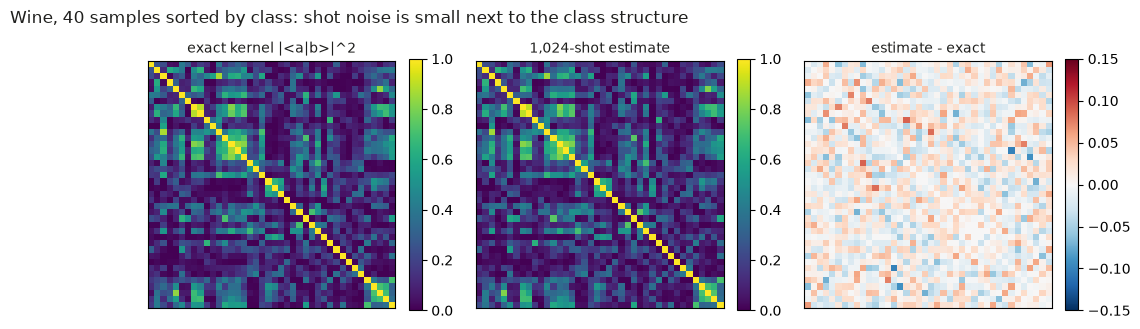

std of (estimate - exact) off the diagonal: 0.028


In [8]:
subset = wine.features[np.argsort(wine.labels, kind="stable")][::3][
    :40
]  # sorted by class to show the block structure
exact = squared_overlap_kernel(subset, subset)
estimate = finite_shot_kernel(
    subset, subset, 1024, np.random.default_rng(0), symmetric=True
)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, matrix, title, cmap, limits in [
    (axes[0], exact, "exact kernel |<a|b>|^2", "viridis", (0, 1)),
    (axes[1], estimate, "1,024-shot estimate", "viridis", (0, 1)),
    (axes[2], estimate - exact, "estimate - exact", "RdBu_r", (-0.15, 0.15)),
]:
    image = ax.imshow(matrix, cmap=cmap, vmin=limits[0], vmax=limits[1])
    ax.set_title(title, color=INK, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
    fig.colorbar(image, ax=ax, fraction=0.046)
fig.suptitle(
    "Wine, 40 samples sorted by class: shot noise is small next to the class structure",
    color=INK,
    x=0.01,
    ha="left",
)
plt.show()
print(
    f"std of (estimate - exact) off the diagonal: {(estimate - exact)[np.triu_indices(len(subset), 1)].std():.3f}"
)

## 6. Small live experiment: Table 1 on Wine and Parkinson's

We now rerun the paper-protocol experiments for Wine and Parkinson's, five seeds each, through the same runner as the stored sweeps (`configs/accuracy_<dataset>_original.json` for the paper's three columns, `configs/accuracy_<dataset>_reference.json` for the exact references). The live values must equal the stored sweep values exactly, because each run is deterministic given its seed.

In [9]:
started = time.perf_counter()
live = {}  # "<dataset>_<config kind>" -> {seed: metrics}
for name in ("wine", "parkinsons"):
    for kind in ("original", "reference"):
        live[f"{name}_{kind}"] = run_live(f"accuracy_{name}_{kind}.json")
print(f"20 live runs in {time.perf_counter() - started:.0f} s")
models = {
    "wine": ["kernel_svm"],
    "parkinsons": ["kernel_svm", "kernel_pca_best_on_test_folds"],
}
for name in ("wine", "parkinsons"):
    gap = check_against_stored(
        live[f"{name}_original"],
        "table1_original",
        f"accuracy_{name}_original",
        [
            (m, mod)
            for m in ("classical_linear", "quantum_centralised", "quantum_distributed")
            for mod in models[name]
        ],
    )
    print(f"{name}: largest |live - stored| = {gap:.1e}")

20 live runs in 3 s
wine: largest |live - stored| = 0.0e+00
parkinsons: largest |live - stored| = 0.0e+00


## 7. Headline reproduction result

### 7.1 Table 1

Paper values next to ours for all 15 cells. Wine and Parkinson's come from the live runs above; Framingham (about 50 s per seed per config) from the stored `table1_original` sweep. Each of our cells shows the five seeds.

In [10]:
DATASETS = {"Wine": "wine", "Parkinson's": "parkinsons", "Framingham": "framingham"}
COLUMNS = {
    "centralised classical": "classical_linear",
    "centralised quantum": "quantum_centralised",
    "distributed quantum": "quantum_distributed",
}
MODELS = {"kernel SVM": "kernel_svm", "kernel PCA": "kernel_pca_best_on_test_folds"}


def table1_values(
    dataset: str, method: str, model: str, metric: str = "accuracy"
) -> np.ndarray:
    if dataset in ("wine", "parkinsons"):
        return live_values(live[f"{dataset}_original"], method, model, metric)
    return stored_values(
        "table1_original", f"accuracy_{dataset}_original", method, model, metric
    )


rows = []
for label, paper in PAPER_VALUES.items():
    if paper["experiment"] != "Table 1":
        continue
    dataset_label, model_label, column = [part.strip() for part in label.split(",")]
    ours = table1_values(DATASETS[dataset_label], COLUMNS[column], MODELS[model_label])
    tolerance = paper["paper_std"] if paper["paper_std"] is not None else 0.02
    rows.append(
        {
            "dataset": dataset_label,
            "model": model_label,
            "column": column,
            "paper": paper["paper"],
            "paper fold std": paper["paper_std"],
            "ours (5 seeds)": mean_std(ours),
            "difference": ours.mean() - paper["paper"],
            "matched": abs(ours.mean() - paper["paper"]) <= tolerance,
            "_seeds": ours,
        }
    )
table1 = pd.DataFrame(rows)
print(f"matched: {table1['matched'].sum()} of {len(table1)} cells")
table1.drop(columns="_seeds")

matched: 12 of 15 cells


,dataset,model,column,paper,paper fold std,ours (5 seeds),difference,matched
0,Wine,kernel SVM,centralised classical,0.9860,0.0172,0.9860 ± 0.0000,-3.9409e-05,True
1,Wine,kernel SVM,centralised quantum,0.8805,NaN,0.9067 ± 0.0190,2.6200e-02,False
2,Wine,kernel SVM,distributed quantum,0.8874,0.0259,0.8957 ± 0.0090,8.3143e-03,True
3,Parkinson's,kernel SVM,centralised classical,0.8196,0.0644,0.8054 ± 0.0126,-1.4166e-02,True
4,Parkinson's,kernel SVM,centralised quantum,0.7875,NaN,0.7725 ± 0.0213,-1.5011e-02,True
5,Parkinson's,kernel SVM,distributed quantum,0.7983,0.0798,0.7557 ± 0.0347,-4.2624e-02,True
6,Parkinson's,kernel PCA,centralised classical,0.7872,0.0716,0.8118 ± 0.0046,2.4578e-02,True
7,Parkinson's,kernel PCA,centralised quantum,0.7451,NaN,0.7033 ± 0.0447,-4.1800e-02,False
8,Parkinson's,kernel PCA,distributed quantum,0.7660,0.0744,0.7002 ± 0.0467,-6.5801e-02,True
9,Framingham,kernel SVM,centralised classical,0.6788,0.0108,0.6894 ± 0.0028,1.0623e-02,True


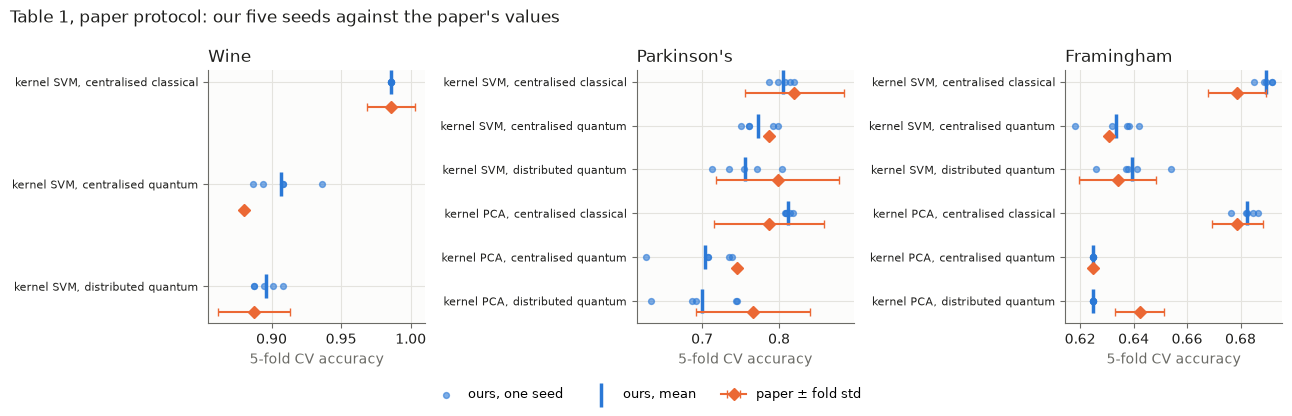

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=False)
for ax, dataset_label in zip(axes, DATASETS):
    part = table1[table1["dataset"] == dataset_label].reset_index(drop=True)
    for y, row in part.iterrows():
        ax.scatter(
            row["_seeds"],
            np.full(5, y),
            color=OURS,
            s=18,
            alpha=0.6,
            label="ours, one seed" if y == 0 else None,
        )
        ax.scatter(
            row["_seeds"].mean(),
            y,
            color=OURS,
            marker="|",
            s=300,
            linewidths=2.5,
            label="ours, mean" if y == 0 else None,
        )
        error = 0 if pd.isna(row["paper fold std"]) else row["paper fold std"]
        ax.errorbar(
            row["paper"],
            y + 0.25,
            xerr=error,
            color=PAPER,
            marker="D",
            markersize=6,
            capsize=3,
            label="paper ± fold std" if y == 0 else None,
        )
    ax.set_yticks(
        range(len(part)),
        [f"{m}, {c}" for m, c in zip(part["model"], part["column"])],
        fontsize=8,
    )
    ax.invert_yaxis()
    ax.set_title(dataset_label, color=INK, loc="left")
    ax.set_xlabel("5-fold CV accuracy", color=MUTED)
    style_axes(ax)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=3,
    fontsize=9,
    frameon=False,
    bbox_to_anchor=(0.5, -0.08),
)
fig.suptitle(
    "Table 1, paper protocol: our five seeds against the paper's values",
    color=INK,
    x=0.01,
    ha="left",
)
fig.tight_layout()
plt.show()

**Observation.** 12 of 15 cells fall within the paper's tolerance. The three others: two single-run paper values without a std (Wine centralised quantum, +0.026; Parkinson's kernel PCA centralised quantum, −0.042) that sit within two seed std of our mean, and Framingham distributed kernel PCA, where our five seeds all give the majority-class rate (0.6249). In every row, centralised classical (a linear SVM) is the highest column; centralised and distributed quantum overlap.

**Inference.** Without noise the two quantum columns differ only by shot noise (Section 4), so their overlap is expected. The paper's single unseeded run sits inside our seed spread in most cells.

**Remaining uncertainty.** The two Wine quantum values of the paper appear in none of the authors' released logs. Our seeds change the oversampling draw, which the authors did not seed.

**Claim impact.** "Distributed ≈ centralised" and "classical is generally highest": **reproduced** under the paper protocol. Whether "comparable to classical" survives a fair baseline is tested in Section 8.

### 7.2 Fig. 4: accuracy against the number of shots (Digits, live)

The paper reports 0.71 / 0.71 / 0.74 / 0.83 for 128 / 256 / 512 / 1,024 shots on a 100-sample, 10-class Digits subset, one run each. The shaded band is the 5–95 % range of our accuracy over 20 alternative fold assignments (stored diagnostic), because the authors' Digits evaluation script, and hence their folds, are not released.

largest |live - stored| = 0.0e+00


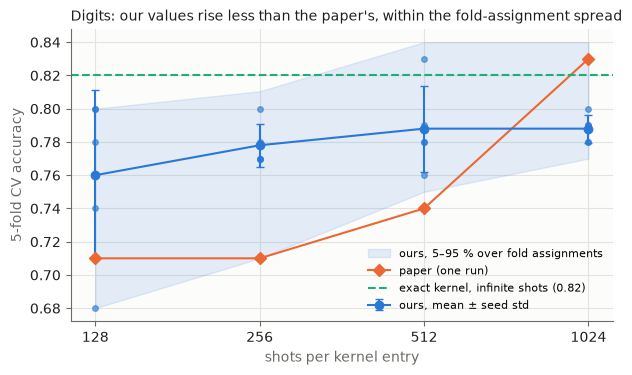

,shots,paper,ours (5 seeds),difference
0,128,0.71,0.7600 ± 0.0510,0.050
1,256,0.71,0.7780 ± 0.0130,0.068
2,512,0.74,0.7880 ± 0.0259,0.048
3,1024,0.83,0.7880 ± 0.0084,-0.042


In [12]:
shots_runs = run_live("shots_digits_original.json")
print(
    f"largest |live - stored| = {check_against_stored(shots_runs, 'shots_original', 'shots_digits_original', [(f'quantum_distributed_{s}_shots', 'kernel_svm') for s in (128, 256, 512, 1024)]):.1e}"
)
gaps = json.loads((RESULTS / "gap_diagnostics.json").read_text())["fold_assignment"]
shot_counts = [128, 256, 512, 1024]
ours = np.array(
    [live_values(shots_runs, f"quantum_distributed_{s}_shots") for s in shot_counts]
)
paper = [PAPER_VALUES[f"Digits, {s:,} shots"]["paper"] for s in shot_counts]
exact_kernel = live_values(shots_runs, "exact_squared_overlap").mean()
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.fill_between(
    range(4),
    [gaps[str(s)]["shuffled_folds"]["p05"] for s in shot_counts],
    [gaps[str(s)]["shuffled_folds"]["p95"] for s in shot_counts],
    color=OURS,
    alpha=0.12,
    label="ours, 5–95 % over fold assignments",
)
for i in range(4):
    ax.scatter(np.full(5, i), ours[i], color=OURS, s=16, alpha=0.6)
ax.errorbar(
    range(4),
    ours.mean(axis=1),
    yerr=ours.std(axis=1, ddof=1),
    color=OURS,
    marker="o",
    capsize=3,
    label="ours, mean ± seed std",
)
ax.plot(range(4), paper, color=PAPER, marker="D", label="paper (one run)")
ax.axhline(
    exact_kernel,
    color=EXACT,
    linestyle="--",
    label=f"exact kernel, infinite shots ({exact_kernel:.2f})",
)
ax.set_xticks(range(4), shot_counts)
ax.set_xlabel("shots per kernel entry", color=MUTED)
ax.set_ylabel("5-fold CV accuracy", color=MUTED)
ax.legend(fontsize=8, frameon=False, loc="lower right")
style_axes(ax)
ax.set_title(
    "Digits: our values rise less than the paper's, within the fold-assignment spread",
    color=INK,
    loc="left",
    fontsize=10,
)
plt.show()
pd.DataFrame(
    {
        "shots": shot_counts,
        "paper": paper,
        "ours (5 seeds)": [mean_std(v) for v in ours],
        "difference": ours.mean(axis=1) - paper,
    }
)

**Observation.** Ours rise from 0.760 to 0.788, against 0.71 → 0.83 in the paper; the steps are smaller than the seed std at 128 shots (0.051). The paper's values lie inside or at the edge of the fold-assignment band.

**Inference.** The trend "more shots, higher accuracy" is weak in our runs; the paper's larger rise is compatible with one run on one fold assignment.

**Remaining uncertainty.** The authors' folds and evaluation script.

**Claim impact.** "More shots raise accuracy": **not clearly reproduced** (direction consistent, size not).

### 7.3 Fig. 3: depolarizing noise (stored sweeps)

Fig. 3 prints no values; the authors' released logs give them. The noise runs need 40–320 s per seed, so they are loaded from the stored sweeps (`noise_original`, and the diagnostic `noise_decomposed_initialize`, designed after the gap was seen).

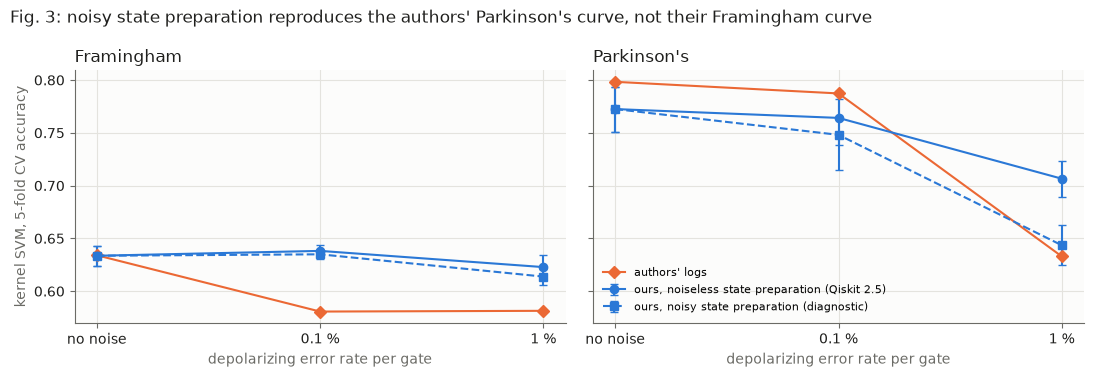

,dataset,noise,authors,"ours, noiseless preparation","ours, noisy preparation"
0,framingham,0.1 %,0.5807,0.6382 ± 0.0054,0.6349 ± 0.0045
1,framingham,1 %,0.5814,0.6228 ± 0.0114,0.6138 ± 0.0076
2,parkinsons,0.1 %,0.7873,0.7641 ± 0.0252,0.7481 ± 0.0336
3,parkinsons,1 %,0.6330,0.7066 ± 0.0171,0.6436 ± 0.0189


In [13]:
authors = {
    "framingham": (0.6340, 0.5807, 0.5814),
    "parkinsons": (0.7983, 0.7873, 0.6330),
}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
rows = []
for ax, dataset in zip(axes, ("framingham", "parkinsons")):
    noiseless_prep = [
        stored_values(
            "noise_original",
            f"noise_{dataset}_original",
            f"quantum_distributed_noise_level_{level}",
        )
        for level in range(3)
    ]
    noisy_prep = [noiseless_prep[0]] + [
        stored_values(
            "noise_decomposed_initialize",
            f"noise_{dataset}_decomposed_initialize",
            f"quantum_distributed_noise_level_{level}_noisy_initialize",
        )
        for level in (1, 2)
    ]
    ax.errorbar(
        range(3),
        [v.mean() for v in noiseless_prep],
        yerr=[v.std(ddof=1) for v in noiseless_prep],
        color=OURS,
        marker="o",
        capsize=3,
        label="ours, noiseless state preparation (Qiskit 2.5)",
    )
    ax.errorbar(
        range(3),
        [v.mean() for v in noisy_prep],
        yerr=[v.std(ddof=1) for v in noisy_prep],
        color=OURS,
        marker="s",
        linestyle="--",
        capsize=3,
        label="ours, noisy state preparation (diagnostic)",
    )
    ax.plot(range(3), authors[dataset], color=PAPER, marker="D", label="authors' logs")
    ax.set_xticks(range(3), ["no noise", "0.1 %", "1 %"])
    ax.set_title(
        {"framingham": "Framingham", "parkinsons": "Parkinson's"}[dataset],
        color=INK,
        loc="left",
    )
    ax.set_xlabel("depolarizing error rate per gate", color=MUTED)
    style_axes(ax)
    for level, name in ((1, "0.1 %"), (2, "1 %")):
        rows.append(
            {
                "dataset": dataset,
                "noise": name,
                "authors": authors[dataset][level],
                "ours, noiseless preparation": mean_std(noiseless_prep[level]),
                "ours, noisy preparation": mean_std(noisy_prep[level]),
            }
        )
axes[0].set_ylabel("kernel SVM, 5-fold CV accuracy", color=MUTED)
axes[1].legend(fontsize=8, frameon=False, loc="lower left")
fig.suptitle(
    "Fig. 3: noisy state preparation reproduces the authors' Parkinson's curve, not their Framingham curve",
    color=INK,
    x=0.01,
    ha="left",
)
fig.tight_layout()
plt.show()
pd.DataFrame(rows)

**Observation.** With the authors' noise model under Qiskit 2.5 (state preparation `initialize` stays native and noiseless), accuracy drops much less than in their logs. Making state preparation noisy — likely what the authors' older Qiskit did — brings Parkinson's to their values (1 %: 0.644 vs 0.633). Framingham stays near 0.61–0.63 against their 0.58 at *both* noise levels.

**Inference.** The noise trend is real, but its size depends on which gates the simulator decomposes, i.e. on the Qiskit version. The authors' Framingham noisy kernels behave like kernels without data information: a fully depolarized kernel gives kernel variance 0.00033 and accuracy 0.59 (stored diagnostic), close to their logged variance 0.000445 at both levels; their own noise model cannot produce this at 0.1 %.

**Remaining uncertainty.** The authors' Qiskit / Aer version. The Framingham gap has no explanation.

**Claim impact.** "Noise lowers accuracy": **trend reproduced, magnitude not**; Framingham **unresolved**.

### 7.4 Fig. 5: random-Fourier-feature error (stored figure)

Relative Frobenius error of the RFF kernel against the number of features D, 5 repetitions, for d = 10 and d = 100,000 (the d = 100,000 run takes minutes, so the stored figure is shown). The error decays as 1/√D (0.593 → 0.113 → 0.019 for D = 32 → 1,024 → 32,768 at σ = 2, d = 10) and is bandwidth-independent at d = 100,000, as in the paper: **reproduced**.

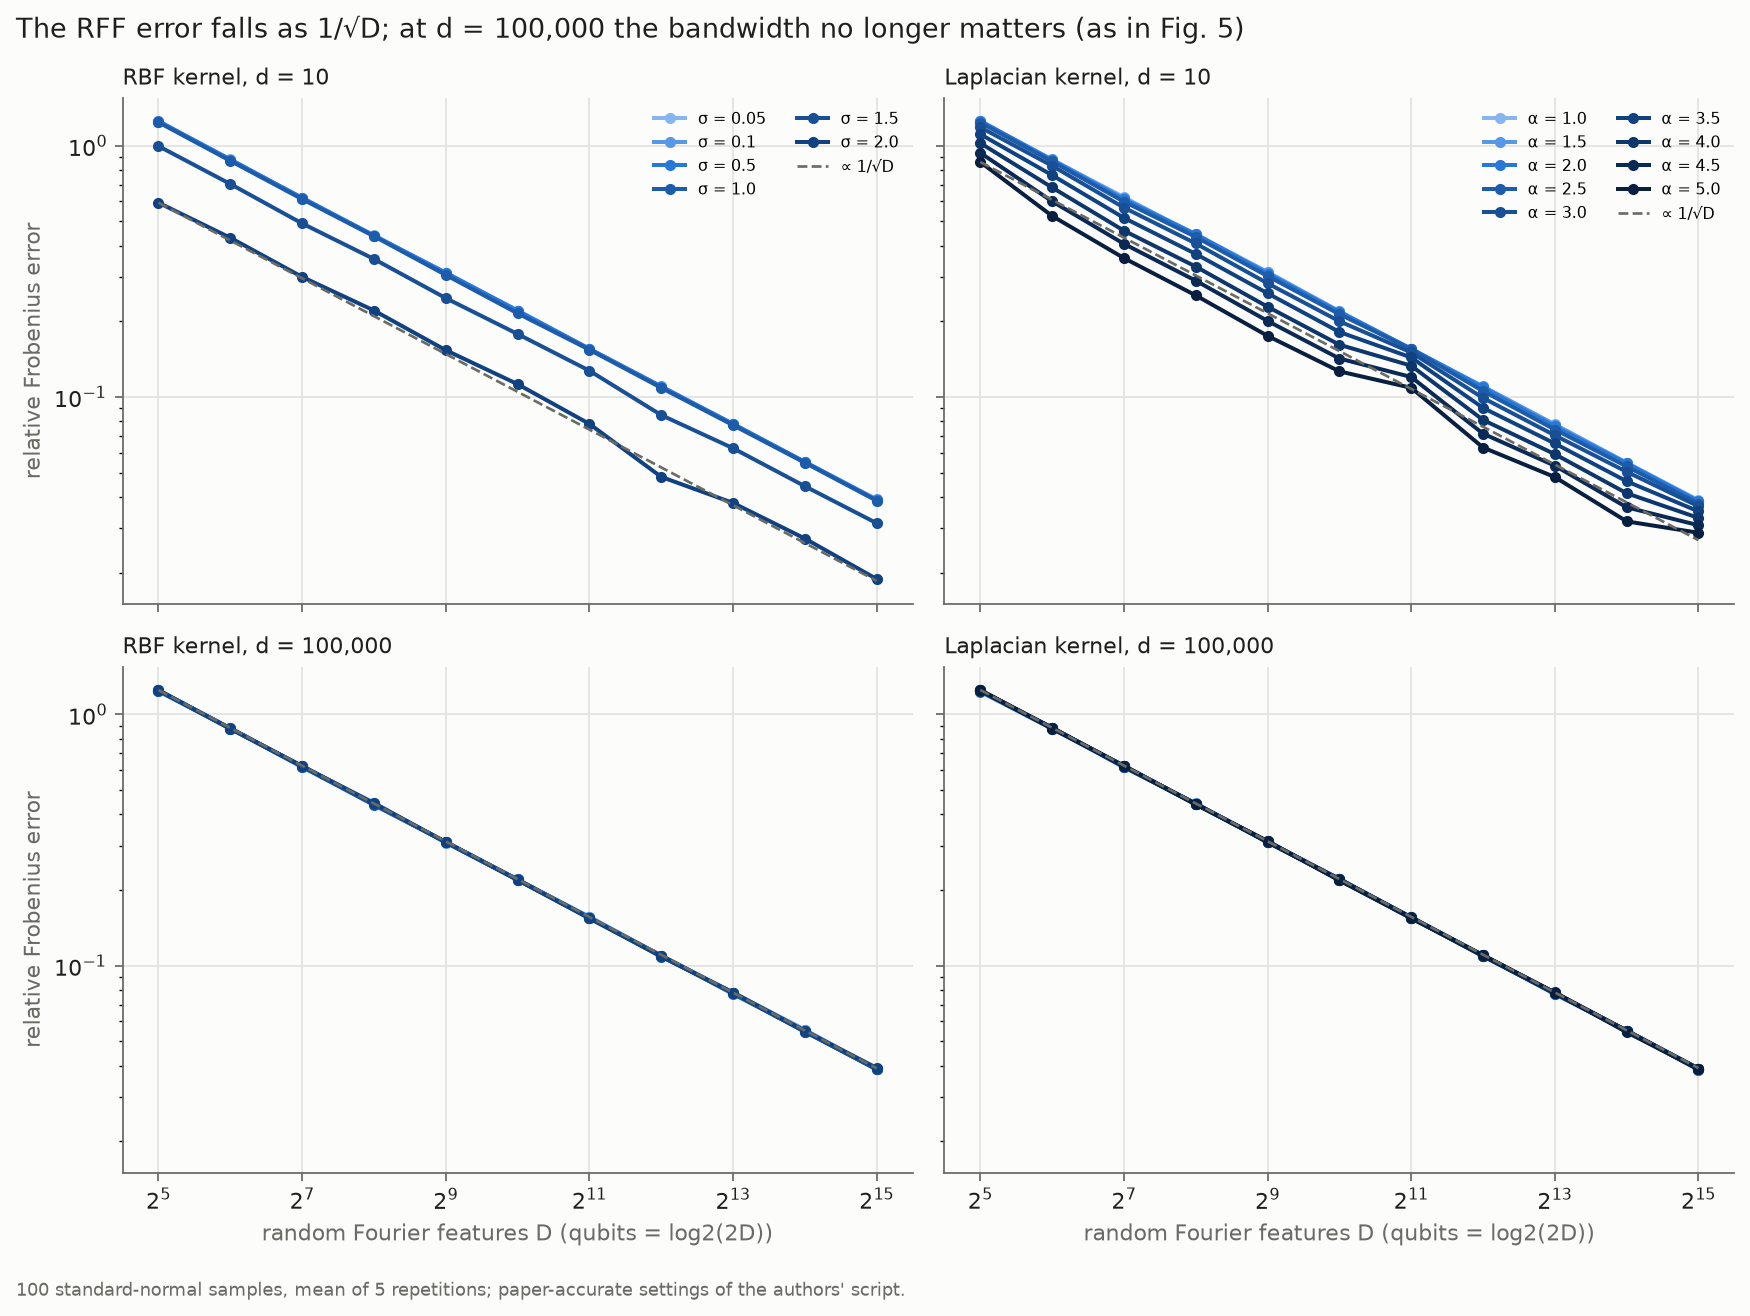

In [14]:
display(Image(filename=str(RESULTS / "rff_error.png"), width=900))

## 8. Fair baseline comparison

The paper's classical column is an **untuned linear SVM under the leaky paper protocol**. That tests "is the quantum kernel comparable to one particular classical kernel", not "is it comparable to classical kernel methods". The fair test, planned before any run:

- **protocol:** corrected (oversampling and every selection inside training folds);
- **baseline:** RBF and polynomial SVMs tuned by inner 5-fold CV, with grids fixed in advance (γ multipliers 10⁻³–10 of 1/(d·Var), degree 2–3, coef0 0–1, the same C grid as the quantum kernel; Framingham C ≤ 10 for runtime);
- **same samples, folds, C grid and seeds** for every system.

Fairness, dimension by dimension (only "same" dimensions are matched):

| Dimension | Quantum kernel | Tuned classical SVM | Matched? |
|---|---|---|---|
| Information and inputs | standardised features | same | same |
| Parameter count | SVM dual coefficients; kernel has none | same SVM; kernel has 1–3 hyperparameters | not matched: the classical kernel has tuned hyperparameters the quantum kernel lacks |
| Training data | training folds, oversampled inside | same | same |
| Optimization | SVM solver, C by inner CV | same solver, C and kernel hyperparameters by inner CV | not matched: larger tuning grid for the classical kernel |
| Tuning budget | 9 C values (7 for Framingham) | 9 C × 5 γ (RBF), × 2 degrees × 2 coef0 (polynomial) | not matched (see above) |
| Compute and wall time | exact simulation; the protocol would need 1,024 circuit executions per kernel entry | closed-form kernel | not matched; not an axis of the claim |
| Evaluation protocol | corrected, stratified 5-fold, seeds 0–4 | same | same |

The paper claims no advantage on compute, so the comparison axis is accuracy (and balanced accuracy) at the same data and protocol. A quantum kernel without hyperparameters cannot be tuned, so giving the classical kernel its usual tuning is the conventional, competent baseline, not a handicap of the quantum side.

Live runs: Wine and Parkinson's, five seeds, under the corrected protocol (`accuracy_<dataset>_corrected.json`: the paper's columns and references; `accuracy_<dataset>_fair_classical.json`: the tuned baselines). Framingham is loaded from the stored sweeps.

In [15]:
started = time.perf_counter()
for name in ("wine", "parkinsons"):
    for kind in ("corrected", "fair_classical"):
        live[f"{name}_{kind}"] = run_live(f"accuracy_{name}_{kind}.json")
print(f"20 live runs in {time.perf_counter() - started:.0f} s")
for name in ("wine", "parkinsons"):
    print(
        name,
        "largest |live - stored|:",
        f"{check_against_stored(live[f'{name}_corrected'], 'table1_corrected', f'accuracy_{name}_corrected', [(m, 'kernel_svm') for m in ('quantum_distributed', 'quantum_centralised', 'classical_linear')]):.1e},",
        f"{check_against_stored(live[f'{name}_fair_classical'], 'fair_comparison', f'accuracy_{name}_fair_classical', [(m, 'kernel_svm') for m in ('tuned_rbf', 'tuned_poly')]):.1e}",
    )

SYSTEMS = {  # label: (config kind, method)
    "distributed quantum kernel": ("corrected", "quantum_distributed"),
    "centralised quantum kernel": ("corrected", "quantum_centralised"),
    "linear SVM (paper's classical column), C tuned": ("corrected", "classical_linear"),
    "tuned RBF SVM": ("fair_classical", "tuned_rbf"),
    "tuned polynomial SVM": ("fair_classical", "tuned_poly"),
    "majority class": ("corrected", "majority_class"),
}
STORED_SWEEP = {"corrected": "table1_corrected", "fair_classical": "fair_comparison"}


def fair_values(dataset: str, system: str, metric: str) -> np.ndarray:
    kind, method = SYSTEMS[system]
    if dataset in ("wine", "parkinsons"):
        return live_values(live[f"{dataset}_{kind}"], method, "kernel_svm", metric)
    return stored_values(
        STORED_SWEEP[kind], f"accuracy_{dataset}_{kind}", method, "kernel_svm", metric
    )


fair = {
    (d, s, m): fair_values(d, s, m)
    for d in DATASETS.values()
    for s in SYSTEMS
    for m in ("accuracy", "balanced_accuracy")
}
pd.DataFrame(
    {
        label: {
            system: f"{mean_std(fair[(d, system, 'accuracy')])} / {fair[(d, system, 'balanced_accuracy')].mean():.3f}"
            for system in SYSTEMS
        }
        for label, d in DATASETS.items()
    }
).rename_axis("kernel SVM: accuracy ± seed std / balanced accuracy")

20 live runs in 48 s
wine largest |live - stored|: 0.0e+00, 0.0e+00
parkinsons largest |live - stored|: 0.0e+00, 0.0e+00


,Wine,Parkinson's,Framingham
kernel SVM: accuracy ± seed std / balanced accuracy,,,
distributed quantum kernel,0.8899 ± 0.0118 / 0.895,0.7821 ± 0.0339 / 0.623,0.8463 ± 0.0013 / 0.501
centralised quantum kernel,0.8914 ± 0.0146 / 0.896,0.7833 ± 0.0200 / 0.622,0.8466 ± 0.0012 / 0.501
"linear SVM (paper's classical column), C tuned",0.9791 ± 0.0000 / 0.983,0.8189 ± 0.0095 / 0.751,0.7913 ± 0.0028 / 0.629
tuned RBF SVM,0.9791 ± 0.0000 / 0.983,0.9271 ± 0.0035 / 0.913,0.8395 ± 0.0013 / 0.512
tuned polynomial SVM,0.9791 ± 0.0000 / 0.983,0.8977 ± 0.0079 / 0.887,0.8362 ± 0.0028 / 0.535
majority class,0.4012 ± 0.0000 / 0.333,0.7565 ± 0.0000 / 0.500,0.8473 ± 0.0000 / 0.500


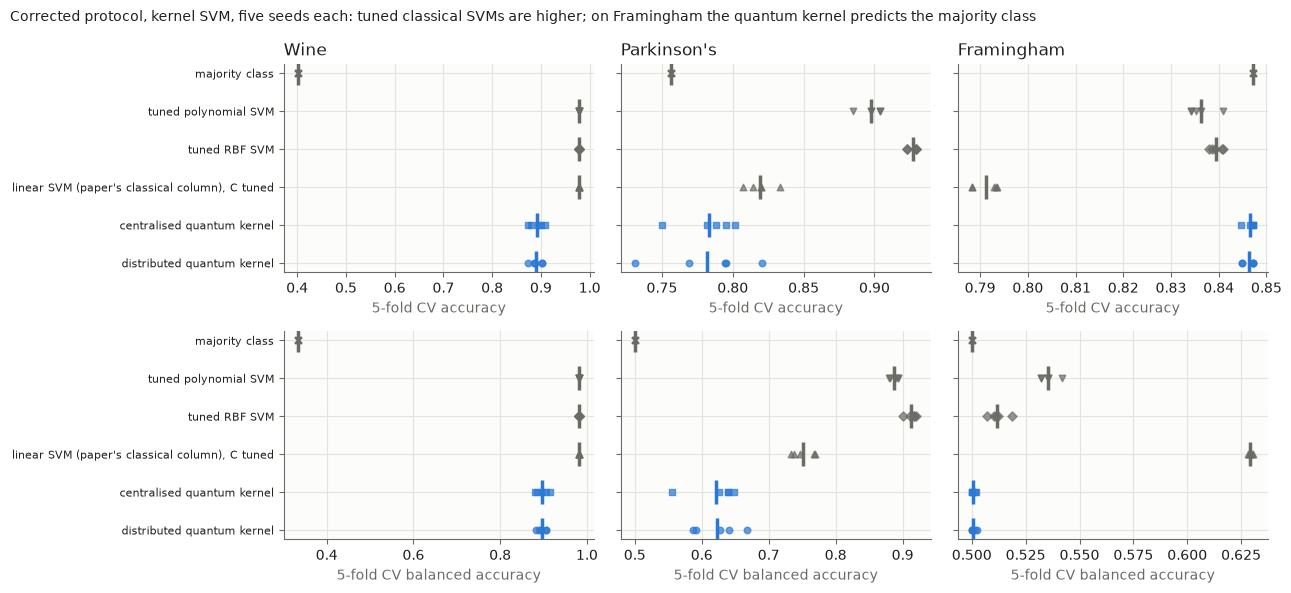

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharey=True)
systems = list(SYSTEMS)
colors = [OURS, OURS, REFERENCE, REFERENCE, REFERENCE, REFERENCE]
markers = ["o", "s", "^", "D", "v", "x"]
for col, (label, dataset) in enumerate(DATASETS.items()):
    for row, metric in enumerate(("accuracy", "balanced_accuracy")):
        ax = axes[row, col]
        for y, system in enumerate(systems):
            values = fair[(dataset, system, metric)]
            ax.scatter(
                values,
                np.full(5, y),
                color=colors[y],
                marker=markers[y],
                s=22,
                alpha=0.7,
            )
            ax.scatter(
                values.mean(), y, color=colors[y], marker="|", s=300, linewidths=2.5
            )
        ax.set_yticks(range(len(systems)), systems, fontsize=8)
        ax.invert_yaxis()
        ax.set_xlabel(f"5-fold CV {metric.replace('_', ' ')}", color=MUTED)
        if row == 0:
            ax.set_title(label, color=INK, loc="left")
        style_axes(ax)
fig.suptitle(
    "Corrected protocol, kernel SVM, five seeds each: tuned classical SVMs are higher; on Framingham the quantum kernel predicts the majority class",
    color=INK,
    x=0.01,
    ha="left",
    fontsize=10,
)
fig.tight_layout()
plt.show()

In [17]:
pairs = [
    ("distributed quantum kernel", "centralised quantum kernel"),
    ("distributed quantum kernel", "tuned RBF SVM"),
    ("distributed quantum kernel", "tuned polynomial SVM"),
    ("distributed quantum kernel", "linear SVM (paper's classical column), C tuned"),
    ("distributed quantum kernel", "majority class"),
]
rows = []
for label, dataset in DATASETS.items():
    for first, second in pairs:
        for metric in ("accuracy", "balanced_accuracy"):
            rows.append(
                {
                    "dataset": label,
                    "first": first,
                    "second": second,
                    "metric": metric,
                    **decide(
                        fair[(dataset, first, metric)], fair[(dataset, second, metric)]
                    ),
                }
            )
decisions = pd.DataFrame(rows)
decisions.pivot_table(
    index=["dataset", "second"],
    columns="metric",
    values=["difference", "verdict"],
    aggfunc="first",
    sort=False,
).rename_axis(index=["dataset", "distributed quantum kernel vs"])

difference  \
metric                                                       accuracy   
dataset     distributed quantum kernel vs                               
Wine        centralised quantum kernel                        -0.0015   
            tuned RBF SVM                                     -0.0892   
            tuned polynomial SVM                              -0.0892   
            linear SVM (paper's classical column), C tuned    -0.0892   
            majority class                                     0.4887   
Parkinson's centralised quantum kernel                        -0.0013   
            tuned RBF SVM                                     -0.1450   
            tuned polynomial SVM                              -0.1157   
            linear SVM (paper's classical column), C tuned    -0.0369   
            majority class                                     0.0256   
Framingham  centralised quantum kernel                        -0.0003   
            tuned RBF SVM                                      0.0069   
            tuned polynomial SVM                               0.0101   
            linear SVM (paper's classical column), C tuned     0.0551   
            majority class                                    -0.0009   

                                                                              \
metric                                                     balanced_accuracy   
dataset     distributed quantum kernel vs                                      
Wine        centralised quantum kernel                           -9.0572e-04   
            tuned RBF SVM                                        -8.7394e-02   
            tuned polynomial SVM                                 -8.7394e-02   
            linear SVM (paper's classical column), C tuned       -8.7394e-02   
            majority class                                        5.6210e-01   
Parkinson's centralised quantum kernel                            1.3406e-03   
            tuned RBF SVM                                        -2.8991e-01   
            tuned polynomial SVM                                 -2.6446e-01   
            linear SVM (paper's classical column), C tuned       -1.2812e-01   
            majority class                                        1.2289e-01   
Framingham  centralised quantum kernel                            1.5763e-05   
            tuned RBF SVM                                        -1.1153e-02   
            tuned polynomial SVM                                 -3.4671e-02   
            linear SVM (paper's classical column), C tuned       -1.2860e-01   
            majority class                                        7.0213e-04   

                                                                  verdict  \
metric                                                           accuracy   
dataset     distributed quantum kernel vs                                   
Wine        centralised quantum kernel                         equivalent   
            tuned RBF SVM                                   second higher   
            tuned polynomial SVM                            second higher   
            linear SVM (paper's classical column), C tuned  second higher   
            majority class                                   first higher   
Parkinson's centralised quantum kernel                         equivalent   
            tuned RBF SVM                                   second higher   
            tuned polynomial SVM                            second higher   
            linear SVM (paper's classical column), C tuned     equivalent   
            majority class                                     equivalent   
Framingham  centralised quantum kernel                         equivalent   
            tuned RBF SVM                                    first higher   
            tuned polynomial SVM                             first higher   
            linear SVM (paper's classical column), C tuned   first high

**Observation** ("first higher" / "second higher" mean beyond 2 σ_pooled; the difference is distributed quantum minus the other system).

- Distributed and centralised quantum kernels are equivalent on all three datasets and both metrics.
- Wine: every classical SVM is higher by 0.089 in accuracy.
- Parkinson's: the tuned RBF SVM is higher by 0.145 in accuracy and 0.29 in balanced accuracy, the tuned polynomial SVM by 0.116 and 0.26. The quantum kernel's accuracy (0.782) cannot be told apart from the majority class (0.757); only its balanced accuracy (0.62) is above it.
- Framingham: the quantum kernel is equivalent to the majority class on both metrics (accuracy 0.846 vs 0.847, balanced accuracy 0.50): it predicts the majority class. Its plain accuracy is therefore higher than the classical SVMs', which trade accuracy for minority recall, and every classical SVM is higher in balanced accuracy.

**Inference.** The swap-test kernel (a squared cosine, Section 3) is a weak fixed kernel on these datasets. The paper's "comparable to classical" depends on comparing against an untuned linear kernel under a protocol whose oversampling leaks test copies into training.

**Remaining uncertainty.** The classical kernels tune hyperparameters the quantum kernel does not have (fairness table). No classical *secure* baseline (secure multiparty computation, homomorphic encryption) was run, so the cost of privacy is not measured.

**Claim impact.** "Distributed ≈ centralised": **reproduced**. "Comparable to classical": **contradicted** against a fair baseline. "Classical is highest": **reproduced, and understated**. No quantum advantage is claimed or observed.

## 9. Controls and ablations

Three controls separate the paper's explanation from simpler ones:

- **Shot noise or kernel?** The *exact* infinite-shot kernel removes shot noise entirely. If it scores like the 1,024-shot kernels, accuracy differences come from the kernel, not from the quantum estimation.
- **Squared or plain cosine?** The *exact cosine* kernel is the "linear kernel" the paper names; the swap test returns its square.
- **Leakage.** The same methods under the paper and the corrected protocols show how much the leaky pipeline inflates accuracy.

In [18]:
rows = []
for label, dataset in (("Wine", "wine"), ("Parkinson's", "parkinsons")):
    for method, name in [
        ("quantum_distributed", "distributed quantum, 1,024 shots"),
        ("exact_squared_overlap", "exact squared cosine (infinite shots)"),
        ("exact_cosine", "exact cosine"),
        ("classical_linear", "linear SVM"),
        ("majority_class", "majority class"),
    ]:
        source = (
            f"{dataset}_original"
            if method in ("quantum_distributed", "classical_linear")
            else f"{dataset}_reference"
        )
        paper_protocol = live_values(live[source], method)
        corrected = live_values(live[f"{dataset}_corrected"], method)
        rows.append(
            {
                "dataset": label,
                "kernel": name,
                "paper protocol": mean_std(paper_protocol),
                "corrected protocol": mean_std(corrected),
                "paper - corrected": paper_protocol.mean() - corrected.mean(),
            }
        )
pd.DataFrame(rows)

,dataset,kernel,paper protocol,corrected protocol,paper - corrected
0,Wine,"distributed quantum, 1,024 shots",0.8957 ± 0.0090,0.8899 ± 0.0118,0.0058
1,Wine,exact squared cosine (infinite shots),0.9012 ± 0.0000,0.8872 ± 0.0000,0.0140
2,Wine,exact cosine,0.9857 ± 0.0000,0.9645 ± 0.0000,0.0212
3,Wine,linear SVM,0.9860 ± 0.0000,0.9791 ± 0.0000,0.0069
4,Wine,majority class,0.4012 ± 0.0000,0.4012 ± 0.0000,0.0000
5,Parkinson's,"distributed quantum, 1,024 shots",0.7557 ± 0.0347,0.7821 ± 0.0339,-0.0264
6,Parkinson's,exact squared cosine (infinite shots),0.7726 ± 0.0161,0.7747 ± 0.0186,-0.0021
7,Parkinson's,exact cosine,0.7915 ± 0.0204,0.8010 ± 0.0163,-0.0095
8,Parkinson's,linear SVM,0.8054 ± 0.0126,0.8189 ± 0.0095,-0.0135
9,Parkinson's,majority class,0.6276 ± 0.0000,0.7565 ± 0.0000,-0.1289


**Observation.**

- *Shot noise:* the exact infinite-shot kernel scores like the 1,024-shot kernel (Wine 0.901 vs 0.896, Parkinson's 0.773 vs 0.756 under the paper protocol, within the seed spread).
- *Squaring:* the plain cosine kernel — the "linear kernel" the paper names — is better than its square, clearly on Wine (0.986 vs 0.901) and slightly on Parkinson's (0.792 vs 0.773).
- *Protocol:* the two protocols do not evaluate the same samples (the paper protocol's subset contains oversampled copies, majority rate 0.628 on Parkinson's against 0.756), so the "paper − corrected" column mixes leakage with class balance and is not a leakage measurement on its own. What can be compared is the ordering: linear SVM > cosine > squared cosine ≈ swap-test kernel under both protocols, on both datasets.

**Inference.** Accuracy is set by the kernel, not by the quantum estimation or by the evaluation pipeline: squaring the cosine similarity is what costs accuracy relative to a linear kernel, before any comparison with a tuned kernel.

**Remaining uncertainty.** The corrected-protocol linear SVM also tunes C, so part of its change between protocols comes from tuning.

**Claim impact.** Supports Section 8: the gap to classical kernels is a property of the swap-test kernel itself.

## 10. Robustness and uncertainty

- **Seeds.** Every comparison above uses five seeds and shows them individually; decisions use the seed std (ddof = 1), so a single lucky seed cannot decide a comparison.
- **Fold assignment.** On the 100-sample Digits subset the fold assignment alone moves accuracy by 0.07–0.12 (5–95 % range, Section 7.2); single-run paper values cannot be matched more closely than that.
- **Class imbalance.** On Framingham accuracy is uninformative (majority rate 0.847 without oversampling); balanced accuracy is the decisive metric there (Section 8).
- **Simulator.** All quantum numbers are simulations. The noiseless shortcut is exact (Section 4); the noisy one agrees with per-shot Aer runs to |Δp₀| ≤ 0.004 at 1 % noise (stored check), 4× below the 1,024-shot noise. The noise results depend on the Qiskit version (Section 7.3).
- **Sweep completeness.** All seven stored sweeps are complete: 130 of 130 planned runs (below). No candidate is selected across a sweep; hyperparameters are chosen inside each run by inner CV.

In [19]:
pd.DataFrame(
    [
        {
            "sweep": k,
            "runs": v["runs"],
            "coverage": v["coverage"],
            "folder": v["folder"],
        }
        for k, v in STORED.items()
    ]
)

,sweep,runs,coverage,folder
0,fair_comparison,25,COMPLETE SWEEP,sweep_fair_comparison_20261021-134946
1,merlin_original,20,COMPLETE SWEEP,sweep_merlin_original_20261021-115717
2,noise_decomposed_initialize,10,COMPLETE SWEEP,sweep_noise_decomposed_initialize_20261021-110925
3,noise_original,10,COMPLETE SWEEP,sweep_noise_original_20261020-173524
4,shots_original,5,COMPLETE SWEEP,sweep_shots_original_20261020-182145
5,table1_corrected,30,COMPLETE SWEEP,sweep_table1_corrected_20261021-111645
6,table1_original,30,COMPLETE SWEEP,sweep_table1_original_20261020-173338


## 11. Photonic assessment: a MerLin swap test

**This is an adaptation, not the paper's method.** Status: *partial MerLin translation*.

**Mapping.** The server's swap test has a photonic counterpart: Hong–Ou–Mandel interference between two registers. Each sample is amplitude-encoded into a register of $m$ modes holding 2 photons, over the $\binom{m}{2}$ collision-free Fock states; one 50:50 beam splitter mixes mode $i$ of each register. With photon-number-resolving detection, the photon-number parity of one output group gives
$$P(\text{even}) = \tfrac12 + \tfrac12 |\langle\psi(x)|\psi(y)\rangle|^2,$$
the swap-test probability. `lib/photonic_merlin.py` builds it as a MerLin `QuantumLayer` (FOCK computation space).

**Not translated.** (1) The teleportation-based distribution: linear-optics Bell measurements succeed with probability at most ½, so teleporting these register states is not deterministic; photons travel themselves, which changes the security argument. (2) The noise study: MerLin's distinguishability noise is not usable on superposed inputs (11.2).

### 11.1 Known-answer check: the photonic kernel is the swap-test kernel

In [20]:
modes = register_modes(wine.features.shape[1])
swap_test = PhotonicSwapTest(modes)
registers = encode_registers(wine.features, modes)
rng = np.random.default_rng(3)
left, right = rng.integers(0, len(registers), 300), rng.integers(0, len(registers), 300)
photonic = swap_test.even_probability(registers[left], registers[right])
expected = 0.5 + 0.5 * np.sum(registers[left] * registers[right], axis=1) ** 2
print(
    f"Wine: {wine.features.shape[1]} features -> {modes} modes per register, 4 photons on {2 * modes} modes"
)
print(
    f"300 random pairs: max |P(even) - (1/2 + 1/2 |<a|b>|^2)| = {np.max(np.abs(photonic - expected)):.1e}"
)

Wine: 13 features -> 6 modes per register, 4 photons on 12 modes
300 random pairs: max |P(even) - (1/2 + 1/2 |<a|b>|^2)| = 6.9e-09


### 11.2 Why the noise study is not translated

Partial photon distinguishability is the natural photonic counterpart of the paper's depolarizing noise. For two identical registers P(even) should stay close to 1 when photons are nearly indistinguishable. The check below (`utils/merlin_noise_check.py`) shows it does for Fock basis states but jumps to 0.77 for superposed states as soon as indistinguishability drops below 1 — the value of an incoherent mixture of the basis states. This is reported to the MerLin team.

In [21]:
from distributed_secure_kernels.utils import merlin_noise_check

merlin_noise_check.main()

MerLin 0.4.1, Perceval 1.3.1, 3 modes per register, 2 photons each
indistinguishability | superposed (0.6, 0, 0.8) | basis (1, 0, 0)
1.0 | 1.0000 | 1.0000
0.9999 | 0.7695 | 0.9999
0.999 | 0.7691 | 0.9990
0.99 | 0.7642 | 0.9901


0.95 | 0.7433 | 0.9513
incoherent-mixture value for the superposed state: 0.7696


### 11.3 Does the photonic kernel preserve the results?

Rule (frozen before the MerLin runs): the adaptation preserves the gate-model result when, for every setting, the difference is within 2 σ_pooled. Wine and Parkinson's run live (paper protocol for Table 1, corrected protocol for the fair comparison); Framingham and Digits (2–10 min per seed) come from the stored `merlin_original` sweep.

In [22]:
started = time.perf_counter()
for name in ("wine", "parkinsons"):
    live[f"{name}_merlin"] = run_live(f"accuracy_{name}_merlin.json")
    live[f"{name}_merlin_corrected"] = run_live(
        f"accuracy_{name}_merlin_corrected.json"
    )
print(f"20 live MerLin runs in {time.perf_counter() - started:.0f} s")
for name in ("wine", "parkinsons"):
    print(
        name,
        "largest |live - stored|:",
        f"{check_against_stored(live[f'{name}_merlin'], 'merlin_original', f'accuracy_{name}_merlin', [('merlin_photonic_swap_test', 'kernel_svm')]):.1e},",
        f"{check_against_stored(live[f'{name}_merlin_corrected'], 'fair_comparison', f'accuracy_{name}_merlin_corrected', [('merlin_photonic_swap_test', 'kernel_svm')]):.1e}",
    )

rows = []
settings = [
    ("Wine, kernel SVM", "wine", "kernel_svm"),
    ("Parkinson's, kernel SVM", "parkinsons", "kernel_svm"),
    ("Parkinson's, kernel PCA", "parkinsons", "kernel_pca_best_on_test_folds"),
    ("Framingham, kernel SVM", "framingham", "kernel_svm"),
    ("Framingham, kernel PCA", "framingham", "kernel_pca_best_on_test_folds"),
]
for label, dataset, model in settings:
    gate = table1_values(dataset, "quantum_distributed", model)
    photonic = (
        live_values(live[f"{dataset}_merlin"], "merlin_photonic_swap_test", model)
        if dataset != "framingham"
        else stored_values(
            "merlin_original",
            "accuracy_framingham_merlin",
            "merlin_photonic_swap_test",
            model,
        )
    )
    rows.append(
        {
            "setting": label,
            "protocol": "paper",
            "gate model": mean_std(gate),
            "MerLin": mean_std(photonic),
            **decide(photonic, gate),
        }
    )
for s in (128, 256, 512, 1024):
    gate = live_values(shots_runs, f"quantum_distributed_{s}_shots")
    photonic = stored_values(
        "merlin_original", "shots_digits_merlin", f"merlin_photonic_swap_test_{s}_shots"
    )
    rows.append(
        {
            "setting": f"Digits, {s:,} shots",
            "protocol": "paper",
            "gate model": mean_std(gate),
            "MerLin": mean_std(photonic),
            **decide(photonic, gate),
        }
    )
for label, dataset in (("Wine", "wine"), ("Parkinson's", "parkinsons")):
    gate = live_values(live[f"{dataset}_corrected"], "quantum_distributed")
    photonic = live_values(
        live[f"{dataset}_merlin_corrected"], "merlin_photonic_swap_test"
    )
    rbf = fair[(dataset, "tuned RBF SVM", "accuracy")]
    rows.append(
        {
            "setting": f"{label}, kernel SVM",
            "protocol": "corrected",
            "gate model": mean_std(gate),
            "MerLin": mean_std(photonic),
            **decide(photonic, gate),
            "tuned RBF SVM": mean_std(rbf),
        }
    )
merlin_table = pd.DataFrame(rows).rename(columns={"verdict": "MerLin vs gate model"})
merlin_table

20 live MerLin runs in 75 s
wine largest |live - stored|: 0.0e+00, 0.0e+00
parkinsons largest |live - stored|: 0.0e+00, 0.0e+00


,setting,protocol,gate model,MerLin,difference,2 sigma pooled,MerLin vs gate model,tuned RBF SVM
0,"Wine, kernel SVM",paper,0.8957 ± 0.0090,0.9085 ± 0.0134,0.0128,0.0228,equivalent,NaN
1,"Parkinson's, kernel SVM",paper,0.7557 ± 0.0347,0.7639 ± 0.0191,0.0083,0.0560,equivalent,NaN
2,"Parkinson's, kernel PCA",paper,0.7002 ± 0.0467,0.7065 ± 0.0447,0.0063,0.0914,equivalent,NaN
3,"Framingham, kernel SVM",paper,0.6393 ± 0.0101,0.6322 ± 0.0111,-0.0070,0.0212,equivalent,NaN
4,"Framingham, kernel PCA",paper,0.6249 ± 0.0000,0.6249 ± 0.0000,0.0000,0.0000,equivalent,NaN
5,"Digits, 128 shots",paper,0.7600 ± 0.0510,0.7280 ± 0.0545,-0.0320,0.1055,equivalent,NaN
6,"Digits, 256 shots",paper,0.7780 ± 0.0130,0.7660 ± 0.0344,-0.0120,0.0520,equivalent,NaN
7,"Digits, 512 shots",paper,0.7880 ± 0.0259,0.8000 ± 0.0187,0.0120,0.0452,equivalent,NaN
8,"Digits, 1,024 shots",paper,0.7880 ± 0.0084,0.8200 ± 0.0187,0.0320,0.0290,first higher,NaN
9,"Wine, kernel SVM",corrected,0.8899 ± 0.0118,0.8969 ± 0.0191,0.0070,0.0318,equivalent,0.9791 ± 0.0000


**Observation.** The photonic kernel matches the swap-test law to about 10⁻⁸. Its accuracies are equivalent to the gate model's in every setting except Digits at 1,024 shots (+0.032 against a tolerance of 0.029). Under the corrected protocol it stays below the tuned RBF SVM, like the gate-model kernel.

**Inference.** Both implementations compute the same kernel; they differ only by independent shot-noise draws, and with 11 comparisons at 2 σ one exceedance is not surprising. The rule is not changed after the fact.

**Hardware assumptions.** Simulation only (MerLin CPU simulator, analytic probabilities, float64; parity drawn as Binomial(shots, P(even))). FOCK computation space with ideal photon-number-resolving detectors (threshold detectors cannot read the parity); 4 photons on 12 (Wine, Framingham), 16 (Parkinson's) or 24 (Digits) modes; ideal state preparation, which linear optics cannot do deterministically; no loss, no postselection; no trainable parameters.

**Claim impact (extension).** The photonic swap test **preserves** the paper's kernel and accuracies, and therefore also its weakness against a fair classical baseline. It shows no photonic advantage. The distributed and secure part does not translate deterministically to linear optics.

## 12. Conclusion

Five outcomes kept apart:

| Question | Answer | Evidence |
|---|---|---|
| Does the software execute? | Yes: every cell above ran, and the live runs equal the stored sweep runs | Sections 6, 7.2, 8, 11.3 |
| Does the method solve the task? | Partly: well above the majority class on Wine and Parkinson's; on Framingham it predicts the majority class | Section 8 |
| Does the paper's metric reproduce? | Table 1 yes (12 of 15 cells); Fig. 3 and Fig. 4 only in trend; Fig. 5 yes | Sections 7.1–7.4 |
| Does the paper's explanation survive controls? | The kernel, not shot noise or the protocol, sets the accuracy; the "linear kernel" is a squared cosine | Sections 3, 4, 9 |
| Does the method beat or match a fair baseline? | No: tuned classical SVMs are higher beyond 2 σ | Section 8 |

**1. What reproduced.** The distributed circuit computes the same swap-test kernel as the centralised one (Section 4.2); distributed ≈ centralised accuracy (Sections 7.1, 8); centralised classical is the highest column (Section 7.1); 12 of 15 Table 1 cells; the RFF error decay of Fig. 5 (Section 7.4).

**2. What did not reproduce.** "Comparable to classical" fails against a tuned classical SVM under a leak-free protocol: −0.089 on Wine, −0.145 on Parkinson's, majority-class predictions on Framingham (Section 8). The polynomial feature map is not normalised and does not give $(a\,x^\top y + c)^d$ (Section 4.4). The size of the noise effect (Section 7.3) and of the shots effect (Section 7.2).

**3. What remains unresolved.** The authors' Framingham noisy values (Section 7.3); the authors' Qiskit version and Digits folds (Sections 7.2, 7.3); the two untraced Wine quantum values of Table 1 (Section 7.1).

**4. What was not attempted.** The security proof (an argument; only the uniformity of the client bits was checked in the stored protocol run); a classical secure baseline (secure multiparty computation, homomorphic encryption); per-shot simulation of every kernel entry (replaced by the validated exact simulation, Section 3); hardware runs.

**5. Reproduction verdict.** **Partially reproduced.** The protocol does what it claims (same kernel as a centralised swap test), and the paper's Table 1 numbers are reproduced, but the accuracy claim relative to classical methods does not survive a fair baseline, and the noise and shots studies reproduce only in trend.

**6. Photonic verdict.** **Partial MerLin translation.** The swap test maps exactly onto 4-photon Hong–Ou–Mandel interference with photon-number-resolving detection and preserves every accuracy within 2 σ but one (Section 11.3). Teleportation and the noise study do not translate (Sections 11, 11.2). No photonic advantage.

### Limitations and deviations

- **Simulation shortcut** instead of per-shot circuit simulation for all accuracy runs (validated in Section 4 and in the stored protocol checks).
- **Seeds:** five seeds instead of the authors' single unseeded run; the oversampler is re-implemented.
- **Corrected protocol and tuned baselines** are additions, not part of the paper; the Framingham C grid of the corrected protocol stops at 10, for runtime.
- **Datasets:** the authors' files; the Parkinson's file is the UCI dataset the code reads, not the one the paper cites; the Framingham file could not be compared with the Kaggle original (login required).
- **Simulator version:** Qiskit 2.5 keeps state preparation noiseless, which changes Fig. 3; the noisy-preparation runs are a post hoc diagnostic.
- **Stored, not live:** Framingham, Fig. 3, Fig. 5 and the MerLin Framingham / Digits runs are loaded from complete stored sweeps, because they take minutes per seed.
- **MerLin:** simulation only, ideal detectors and state preparation; the Framingham MerLin run under the corrected protocol was not made (the kernel equals the gate-model kernel).

In [23]:
print(f"Notebook executed in {time.perf_counter() - NOTEBOOK_START:.0f} s")

Notebook executed in 129 s
